# Hessian-SIM: 2x super-resolution by structured illumination

This notebook walks through the full Hessian-SIM reconstruction pipeline on the
2-beam simulated dataset shipped with the task. It is entirely driven by the
precomputed reference outputs in `evaluation/reference_outputs/`, so it runs in
seconds. The **commented-out** cell at the bottom shows how to regenerate
everything from scratch by calling `main.py`.

## Story

1. **Problem.** A fluorescence microscope has a diffraction-limited cutoff
   frequency. Structured illumination multiplies the sample by a cosine grating
   and encodes high-resolution content into the observable passband.
2. **Pipeline.**
    1. Estimate the pattern wavevectors `k_a` from cross-correlation of the
       separated bands.
    2. Estimate the modulation depth `m_a` and phase offsets `φ_{a,p}` from
       histograms of the complex modulation map.
    3. Wiener-recombine the bands into a 2x super-resolved image.
    4. Denoise the Wiener reconstruction with a split-Bregman Hessian solver
       (and compare against a TV baseline).
3. **Result.** A 2x resolution improvement over the widefield image, with
   noise suppressed by the Hessian prior and without the staircase artefacts
   typical of first-order TV.

In [2]:
%matplotlib inline
import json
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, fftshift

ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from src.visualization import compute_widefield, upsample_widefield, ncc, nrmse

REF = os.path.join(ROOT, 'evaluation', 'reference_outputs')
DATA = os.path.join(ROOT, 'data')

## 1. Load the raw data and metadata

In [3]:
raw = np.load(os.path.join(DATA, 'raw_data.npz'))['raw_frames'][0]
with open(os.path.join(DATA, 'meta_data.json')) as f:
    meta = json.load(f)

print('raw stack shape :', raw.shape)
print('dtype            :', raw.dtype)
print('frames / time    :', meta['frames_per_timepoint'], '= nangles * nphases')
print('n_timepoints     :', meta['n_timepoints'])
print('wavelength, NA   :', meta['wavelength_nm'], 'nm,', meta['numerical_aperture'])
print('pixel size       :', meta['pixel_size_nm'], 'nm')

raw stack shape : (72, 256, 256)
dtype            : float32
frames / time    : 6 = nangles * nphases
n_timepoints     : 12
wavelength, NA   : 488 nm, 0.9
pixel size       : 65 nm


## 2. Widefield reference

Incoherent average of the raw frames — what the microscope would produce
without structured illumination.

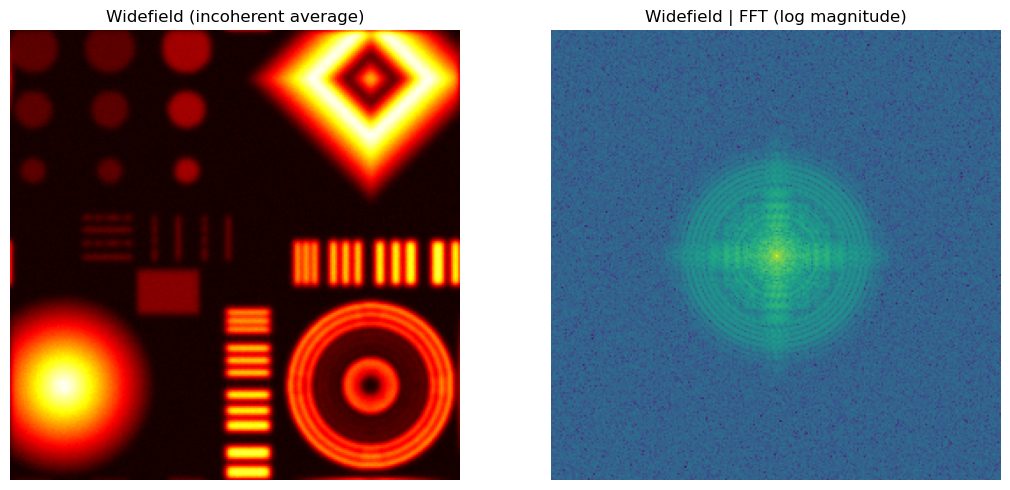

In [4]:
wf = compute_widefield(raw, meta['nangles'], meta['nphases'])

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(wf, cmap='hot')
ax[0].set_title('Widefield (incoherent average)')
ax[0].axis('off')
ax[1].imshow(np.log1p(np.abs(fftshift(fft2(wf)))), cmap='viridis')
ax[1].set_title('Widefield | FFT (log magnitude)')
ax[1].axis('off')
plt.tight_layout()
plt.show()

## 3. Estimated SIM pattern parameters

In [5]:
sim_params = np.load(os.path.join(REF, 'sim_parameters.npz'))
print('zuobiaox (pattern x) :', sim_params['zuobiaox'].ravel())
print('zuobiaoy (pattern y) :', sim_params['zuobiaoy'].ravel())
print('c6 (modulation)      :', sim_params['c6'])
print('angle6 (phase)       :', sim_params['angle6'])

zuobiaox (pattern x) : [512.         511.97021484 512.02978516 512.         634.52587891
 389.47412109]
zuobiaoy (pattern y) : [512.         634.76867676 389.23132324 512.         518.11669922
 505.88330078]
c6 (modulation)      : [0.6  0.48 0.5  0.4 ]
angle6 (phase)       : [-2.22159265  2.25840735 -2.72159265 -0.62159265]


## 4. Wiener-SIM, Hessian-SIM and TV-SIM reconstructions

All three stacks have shape `(n_timepoints, 2*sy, 2*sx)`. We display the
central time point.

In [6]:
wiener = np.load(os.path.join(REF, 'wiener_sim.npz'))['data'][0]
hessian = np.load(os.path.join(REF, 'hessian_sim.npz'))['data'][0]
tv = np.load(os.path.join(REF, 'tv_sim.npz'))['data'][0]

print('wiener / hessian / tv stacks :', wiener.shape, hessian.shape, tv.shape)
t = wiener.shape[0] // 2

wiener / hessian / tv stacks : (12, 512, 512) (12, 512, 512) (12, 512, 512)


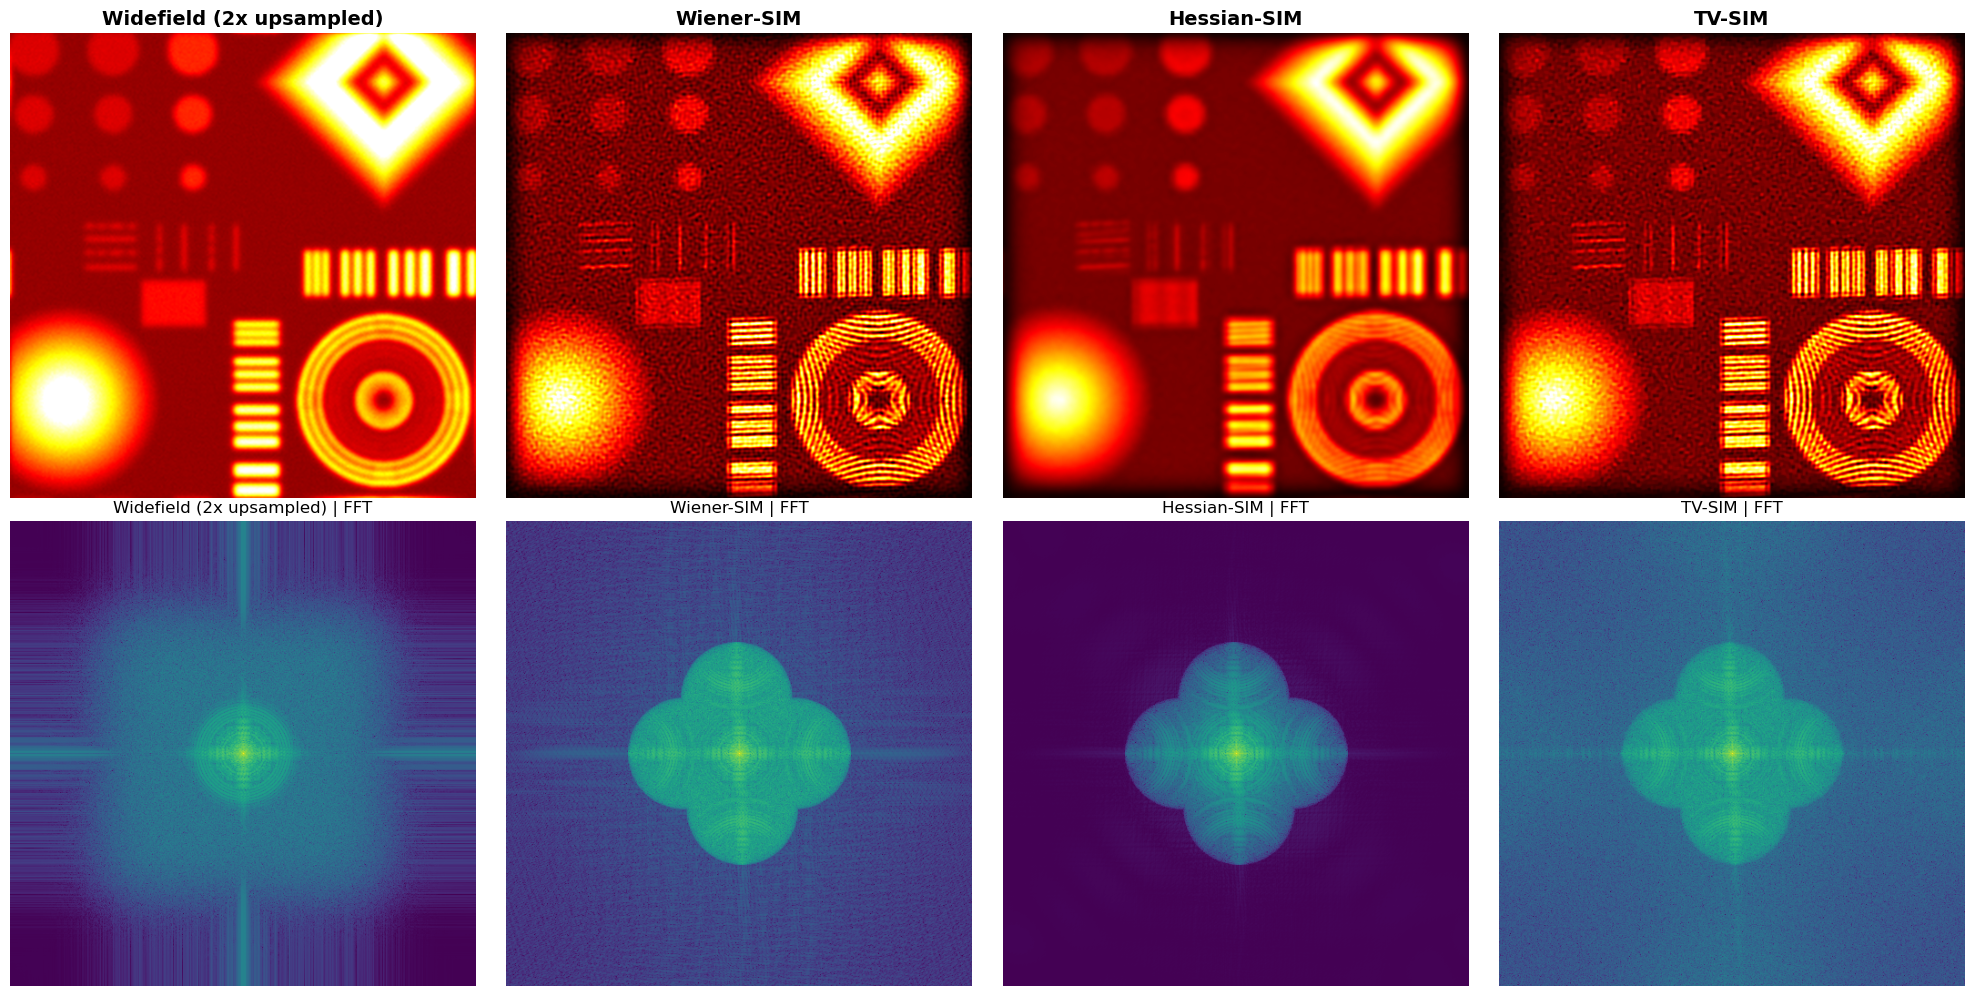

In [7]:
wf_up = upsample_widefield(wf, wiener.shape[1:])
wf_up = wf_up / (wf_up.max() + 1e-12) * wiener[t].max()

images = [wf_up, wiener[t], hessian[t], tv[t]]
titles = ['Widefield (2x upsampled)', 'Wiener-SIM', 'Hessian-SIM', 'TV-SIM']
vmax = np.percentile(wiener[t][wiener[t] > 0], 99.5)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, (img, title) in enumerate(zip(images, titles)):
    axes[0, i].imshow(img, cmap='hot', vmin=0, vmax=vmax)
    axes[0, i].set_title(title, fontsize=14, fontweight='bold')
    axes[0, i].axis('off')
for i, (img, title) in enumerate(zip(images, titles)):
    ft = np.log1p(np.abs(fftshift(fft2(img))))
    axes[1, i].imshow(ft, cmap='viridis')
    axes[1, i].set_title(f'{title} | FFT', fontsize=12)
    axes[1, i].axis('off')
plt.tight_layout()
plt.show()

## 5. Zoomed centre comparison

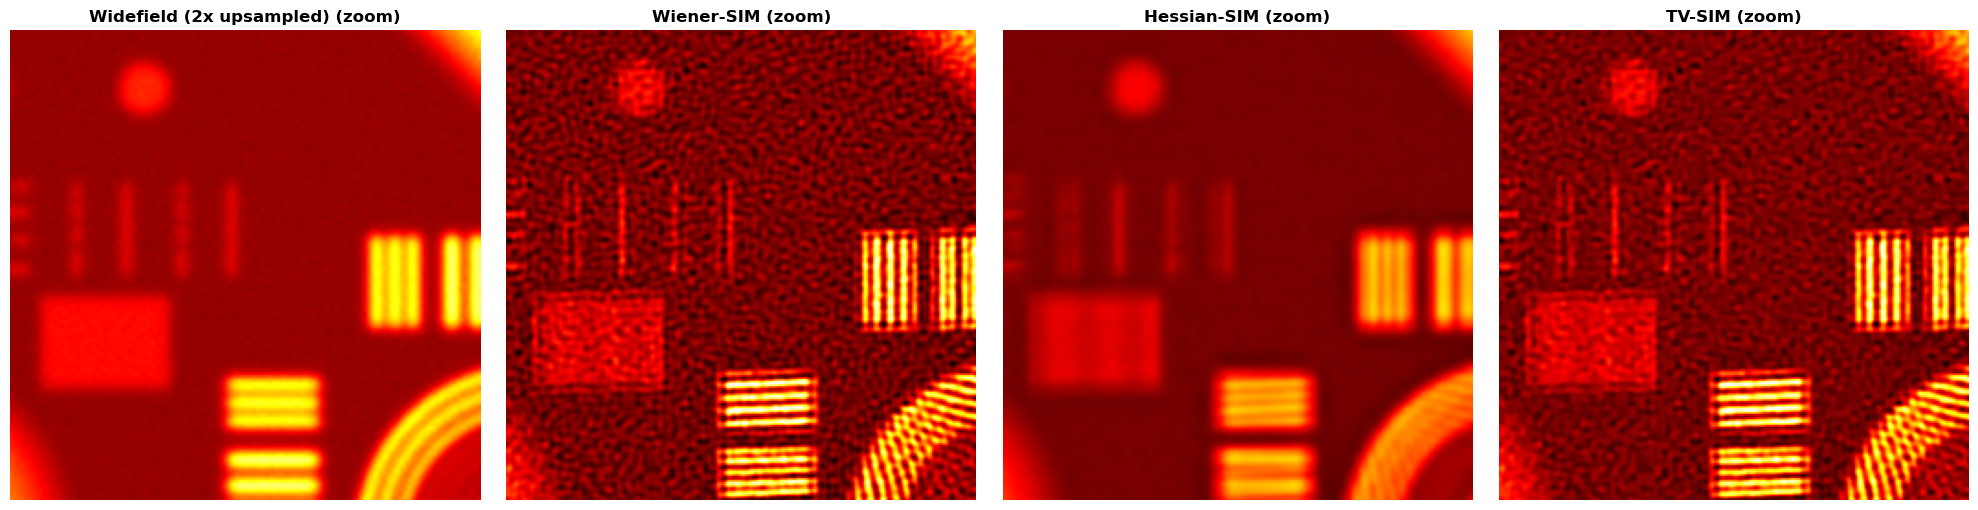

In [8]:
cy, cx = wiener[t].shape[0] // 2, wiener[t].shape[1] // 2
qs = min(cy, cx) // 2
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, (img, title) in enumerate(zip(images, titles)):
    axes[i].imshow(img[cy - qs:cy + qs, cx - qs:cx + qs], cmap='hot', vmin=0, vmax=vmax)
    axes[i].set_title(f'{title} (zoom)', fontsize=12, fontweight='bold')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 6. Line profiles

Line profiles through the centre reveal how Hessian denoising removes
noise while TV introduces piecewise-constant plateaus.

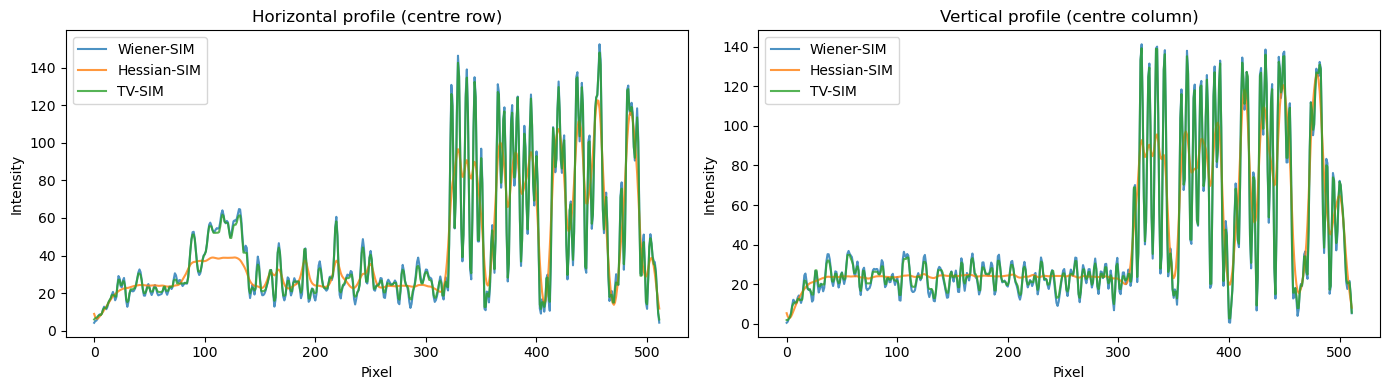

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
row = wiener[t].shape[0] // 2
col = wiener[t].shape[1] // 2
for img, title, c in zip(
    [wiener[t], hessian[t], tv[t]],
    ['Wiener-SIM', 'Hessian-SIM', 'TV-SIM'],
    ['tab:blue', 'tab:orange', 'tab:green'],
):
    axes[0].plot(img[row, :], label=title, alpha=0.8, color=c)
    axes[1].plot(img[:, col], label=title, alpha=0.8, color=c)
axes[0].set_title('Horizontal profile (centre row)')
axes[1].set_title('Vertical profile (centre column)')
for a in axes:
    a.set_xlabel('Pixel'); a.set_ylabel('Intensity'); a.legend()
plt.tight_layout()
plt.show()

## 7. Quantitative metrics

Since no noise-free ground truth exists for the simulation, we evaluate
the Hessian-SIM and TV-SIM denoisers against the Wiener-SIM reference on
the same time point.

In [10]:
with open(os.path.join(ROOT, 'evaluation', 'metrics.json')) as f:
    metrics = json.load(f)
print(json.dumps(metrics, indent=2))

print()
print('Recomputed here:')
print(f"  Hessian  NCC={ncc(hessian[t], wiener[t]):.4f}  NRMSE={nrmse(hessian[t], wiener[t]):.4f}")
print(f"  TV       NCC={ncc(tv[t],      wiener[t]):.4f}  NRMSE={nrmse(tv[t],      wiener[t]):.4f}")

{
  "baseline": [
    {
      "method": "Hessian-SIM denoise vs Wiener-SIM reference",
      "ncc_vs_ref": 0.9787069054901042,
      "nrmse_vs_ref": 0.06242783141537759
    },
    {
      "method": "TV-SIM denoise vs Wiener-SIM reference",
      "ncc_vs_ref": 0.9996028817250916,
      "nrmse_vs_ref": 0.008626522829627326
    }
  ],
  "ncc_boundary": 0.8808362149410938,
  "nrmse_boundary": 0.06867061455691535
}

Recomputed here:
  Hessian  NCC=0.9787  NRMSE=0.0624
  TV       NCC=0.9996  NRMSE=0.0086


## 8. Reproduce from scratch

Uncomment the cell below to run the full pipeline (takes ~1 minute).
It will overwrite the reference outputs and the metrics file.

In [10]:
# import subprocess
# subprocess.run(['python', 'main.py'], cwd=ROOT, check=True)

## Conclusion

The Hessian-SIM pipeline successfully recovers a 2x super-resolved
fluorescence image from six phase-shifted 2-beam SIM frames per time
point. Compared to widefield, the FFT shows a visibly extended
frequency support — the core mechanism of SIM. The Hessian prior
suppresses reconstruction noise without introducing the staircase
artefacts of first-order TV, and operates jointly across time so that
the output sequence is temporally stable.